In [1]:
import os
import json
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from PIL import Image

DATA_DIR = Path("../data")
IMAGE_DIR = DATA_DIR / "images"

train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")

with open(DATA_DIR / "train_pairs.json") as f:
    train_pairs = json.load(f)

with open(DATA_DIR / "test_pairs.json") as f:
    test_pairs = json.load(f)

print("Dataset loaded successfully!")
print("Training queries:", len(train))
print("Test queries:", len(test))
print("Training pairs:", len(train_pairs["pairs"]))
print("Test pairs:", len(test_pairs["pairs"]))

Dataset loaded successfully!
Training queries: 2495
Test queries: 577
Training pairs: 392
Test pairs: 98


In [2]:
display(train.head())
display(train.describe(include="all"))

print("Training columns:", train.columns.tolist())
print("Test columns:", test.columns.tolist())

print("\nUnique training images:",
      pd.concat([train.source_image, train.target_image]).nunique())

print("Unique test images:",
      pd.concat([test.source_image, test.target_image]).nunique())

print("Unique training pairs:", train.pair_id.nunique())
print("Unique test pairs:", test.pair_id.nunique())

,id,pair_id,source_image,target_image,query_index,source_x,source_y,target_points,scale
0,train_q_02450,train_pair_0385,images/train/img_0061.jpeg,images/train/img_0439.jpeg,0,165.000000,256.000000,"[[413.27763496143956,309.5398457583548],[443.2...",53.393830
1,train_q_01710,train_pair_0276,images/train/img_0180.jpeg,images/train/img_0284.jpeg,7,458.052632,200.894737,"[[312.5,292.0]]",298.100000
2,train_q_01371,train_pair_0221,images/train/img_0644.jpeg,images/train/img_0406.jpeg,2,267.000000,375.000000,"[[293.5,325.0]]",330.000000
3,train_q_00157,train_pair_0023,images/train/img_0092.jpeg,images/train/img_0217.jpeg,2,165.000000,381.000000,"[[346.0,276.0]]",62.072851
4,train_q_00952,train_pair_0152,images/train/img_0451.jpeg,images/train/img_0358.jpeg,6,106.900000,139.700000,"[[35.0,181.0]]",319.000000


,id,pair_id,source_image,target_image,query_index,source_x,source_y,target_points,scale
count,2495,2495,2495,2495,2495.000000,2495.000000,2495.000000,2495,2495.000000
unique,2495,392,321,235,NaN,NaN,NaN,930,NaN
top,train_q_00454,train_pair_0245,images/train/img_0270.jpeg,images/train/img_0415.jpeg,NaN,NaN,NaN,"[[235.3924731182796,239.59677419354838],[229.3...",NaN
freq,1,18,29,87,NaN,NaN,NaN,27,NaN
mean,NaN,NaN,NaN,NaN,4.111824,248.239246,212.713171,NaN,265.098514
std,NaN,NaN,NaN,NaN,3.201706,145.680950,115.825373,NaN,206.684387
min,NaN,NaN,NaN,NaN,0.000000,2.500000,2.000000,NaN,29.700000
25%,NaN,NaN,NaN,NaN,2.000000,142.191176,126.073383,NaN,89.488532
50%,NaN,NaN,NaN,NaN,4.000000,235.000000,204.000000,NaN,221.100000
75%,NaN,NaN,NaN,NaN,6.000000,334.714912,285.000000,NaN,377.300000


Training columns: ['id', 'pair_id', 'source_image', 'target_image', 'query_index', 'source_x', 'source_y', 'target_points', 'scale']
Test columns: ['id', 'pair_id', 'source_image', 'target_image', 'query_index', 'source_x', 'source_y']

Unique training images: 517
Unique test images: 129
Unique training pairs: 392
Unique test pairs: 98


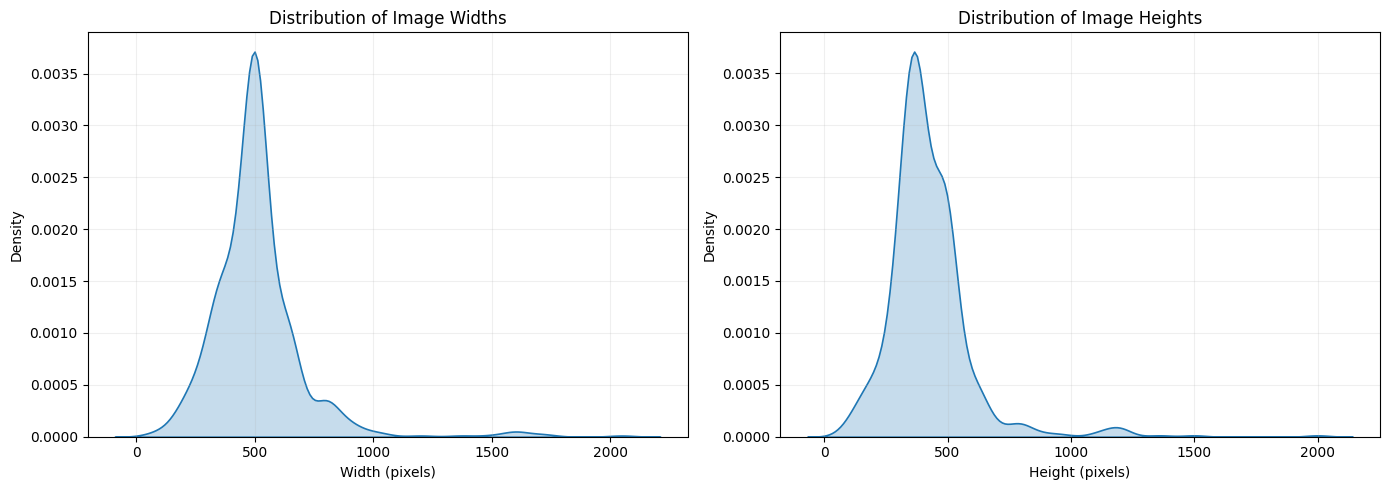

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.kdeplot(image_stats["width"], fill=True, linewidth=1.2, ax=axes[0])
axes[0].set_title("Distribution of Image Widths")
axes[0].set_xlabel("Width (pixels)")
axes[0].set_ylabel("Density")

sns.kdeplot(image_stats["height"], fill=True, linewidth=1.2, ax=axes[1])
axes[1].set_title("Distribution of Image Heights")
axes[1].set_xlabel("Height (pixels)")
axes[1].set_ylabel("Density")

for ax in axes:
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [8]:
def show_pair(index=None):

    if index is None:
        index = random.randrange(len(train))

    row = train.iloc[index]

    source = Image.open(DATA_DIR / row["source_image"]).convert("RGB")
    target = Image.open(DATA_DIR / row["target_image"]).convert("RGB")

    target_points = json.loads(row["target_points"])

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    axes[0].imshow(source)
    axes[0].scatter(row["source_x"], row["source_y"],
                    color="red", s=80, marker="x")
    axes[0].set_title("Source image")

    axes[1].imshow(target)

    for x, y in target_points:
        axes[1].scatter(x, y, color="lime", s=80, marker="x")

    axes[1].set_title("Target image")

    for ax in axes:
        ax.axis("off")

    plt.suptitle(f"Pair: {row['pair_id']} | Query: {row['id']}")
    plt.tight_layout()
    plt.show()

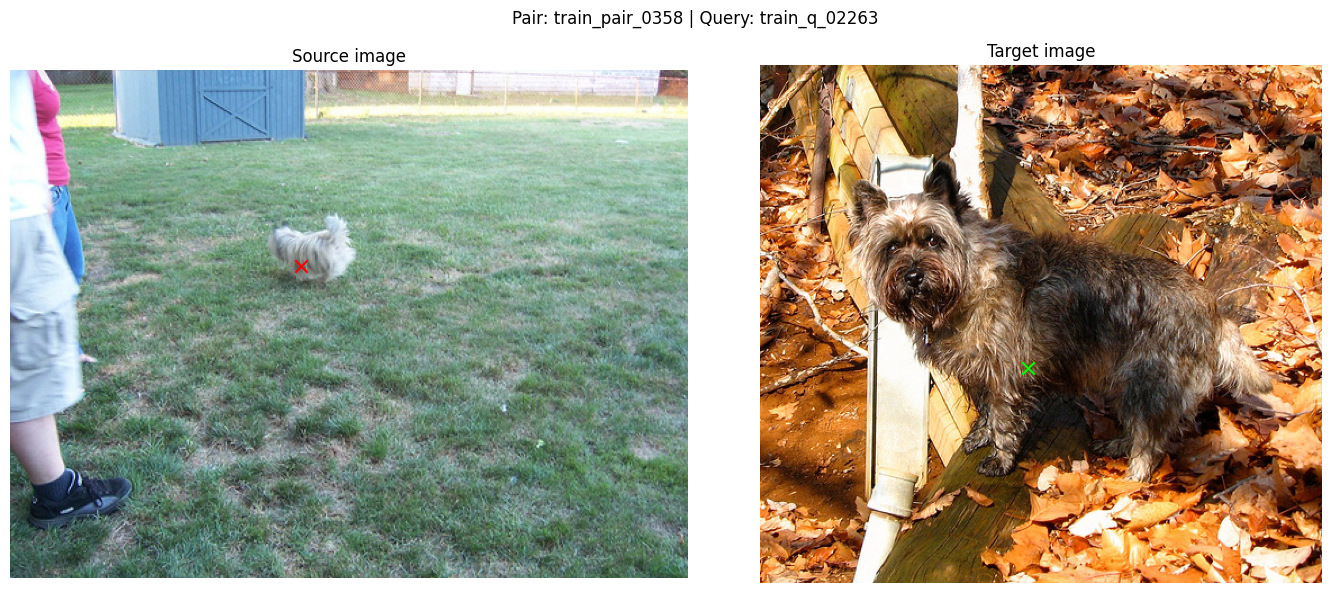

In [12]:
show_pair()

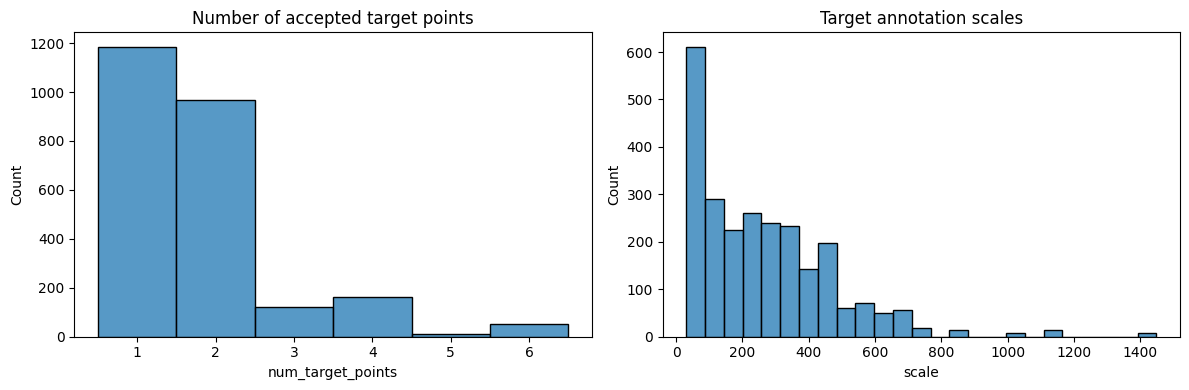

In [13]:
train["num_target_points"] = train["target_points"].apply(
    lambda x: len(json.loads(x))
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(train["num_target_points"], discrete=True, ax=axes[0])
axes[0].set_title("Number of accepted target points")

sns.histplot(train["scale"], bins=25, ax=axes[1])
axes[1].set_title("Target annotation scales")

plt.tight_layout()
plt.show()

,pair_id,source_width,source_height,source_aspect_ratio,source_pixels,source_mean_R,source_mean_G,source_mean_B,source_brightness,source_saturation,target_width,target_height,target_aspect_ratio,target_pixels,target_mean_R,target_mean_G,target_mean_B,target_brightness,target_saturation
0,train_pair_0385,640,480,1.333333,307200,0.557326,0.528982,0.520797,0.631626,0.372235,640,478,1.338912,305920,0.593057,0.567884,0.539650,0.624335,0.230758
1,train_pair_0276,500,375,1.333333,187500,0.425488,0.424518,0.402320,0.461248,0.226238,333,500,0.666000,166500,0.400170,0.397890,0.310539,0.428813,0.332952
2,train_pair_0221,400,600,0.666667,240000,0.450280,0.424235,0.401892,0.471521,0.234897,375,500,0.750000,187500,0.433363,0.387011,0.389075,0.454072,0.204391
3,train_pair_0023,640,559,1.144902,357760,0.302111,0.428334,0.548808,0.592755,0.523469,640,421,1.520190,269440,0.287654,0.317692,0.146915,0.350982,0.552498
4,train_pair_0152,199,172,1.156977,34228,0.549338,0.474285,0.394371,0.549485,0.288559,640,480,1.333333,307200,0.404109,0.296404,0.213390,0.411387,0.566989


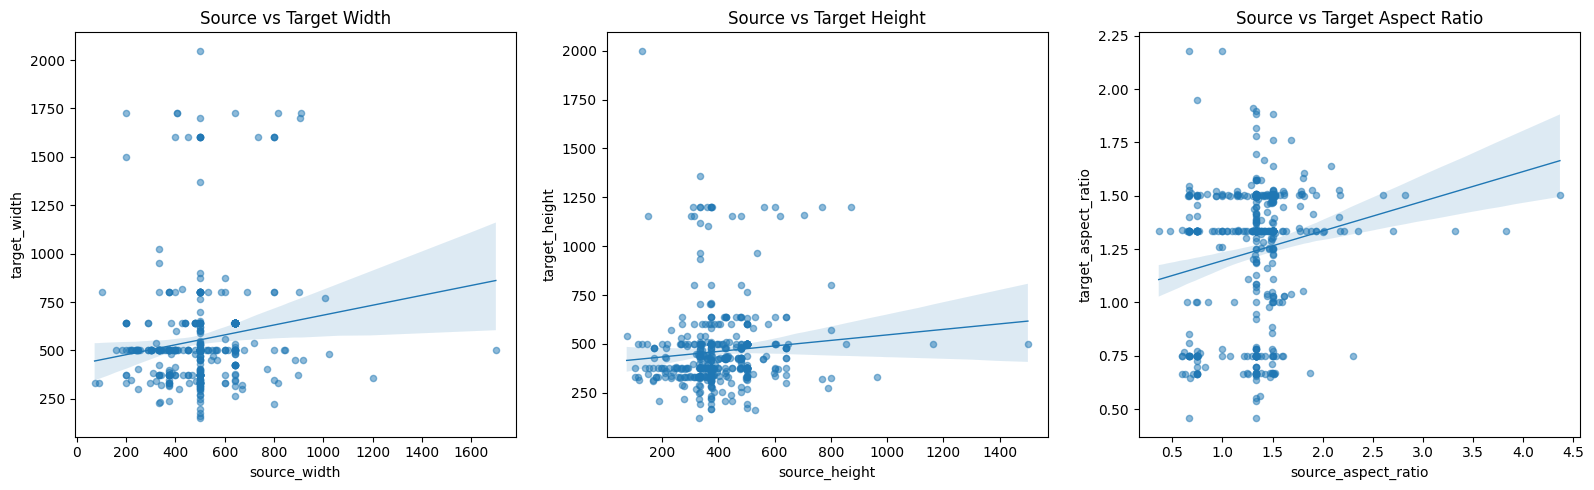

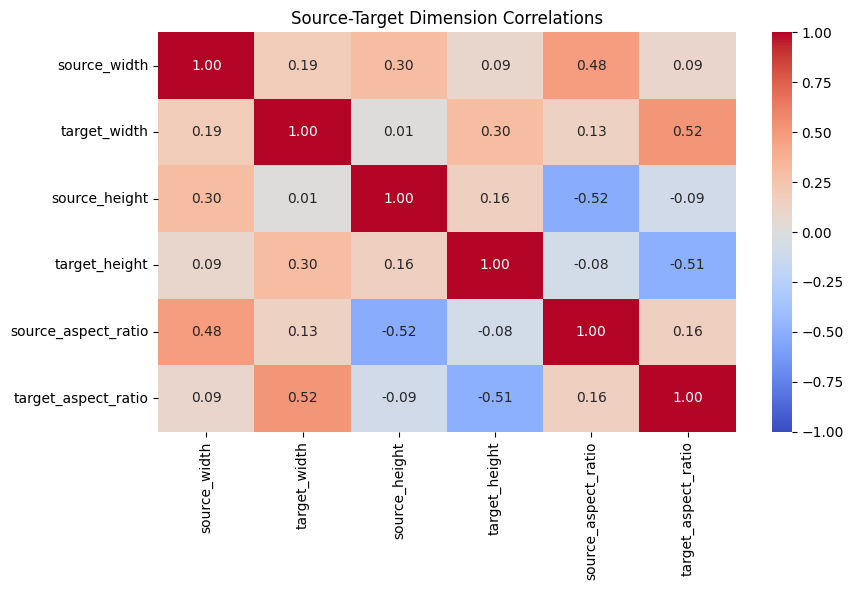

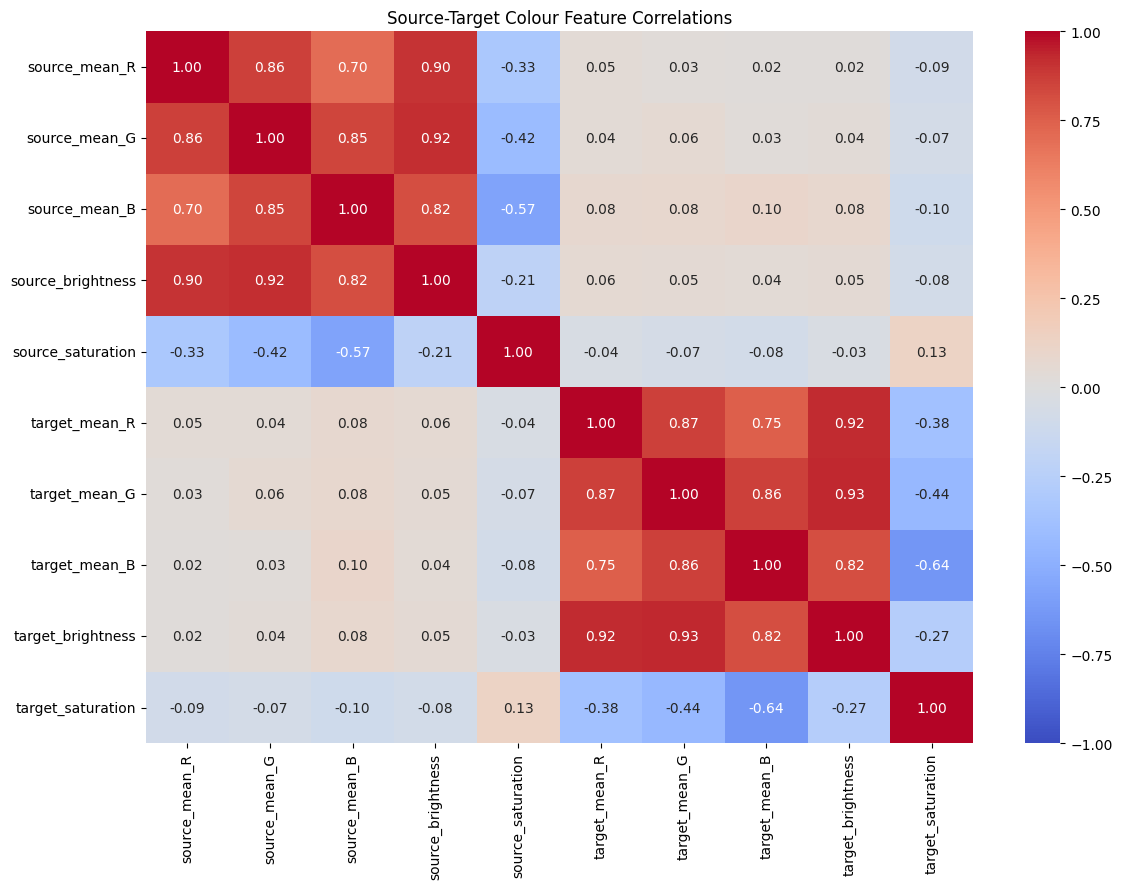

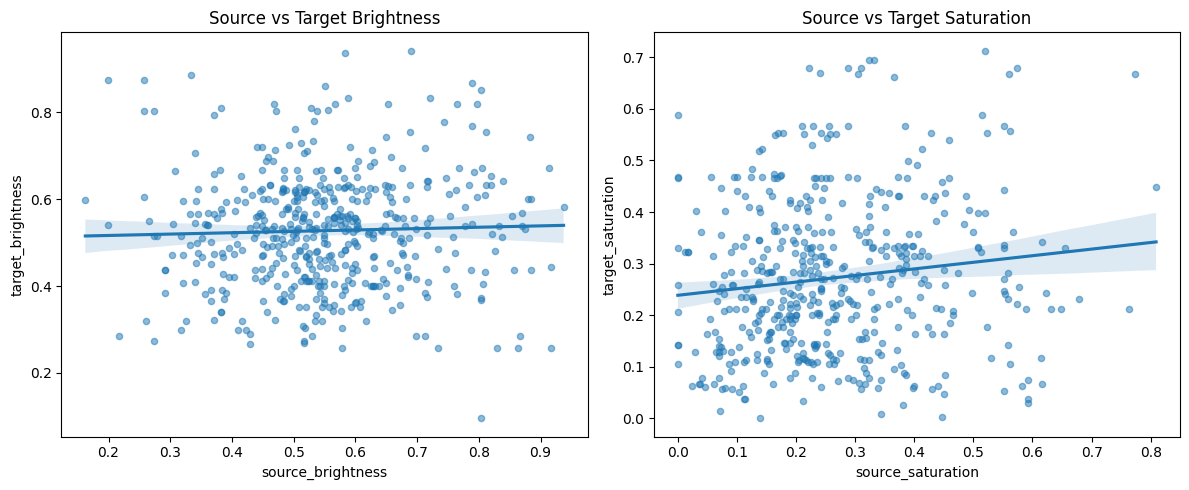

,width_difference,height_difference,aspect_ratio_difference,brightness_difference,saturation_difference
count,490.000,490.000,490.000,490.000,490.000
mean,0.222,0.295,-0.075,-0.023,0.007
std,0.828,0.987,0.466,0.190,0.197
min,-0.719,-0.691,-2.867,-0.708,-0.563
25%,-0.127,-0.112,-0.279,-0.142,-0.099
50%,0.000,0.017,-0.004,-0.017,0.010
75%,0.299,0.378,0.164,0.092,0.127
max,7.597,14.385,1.514,0.676,0.587


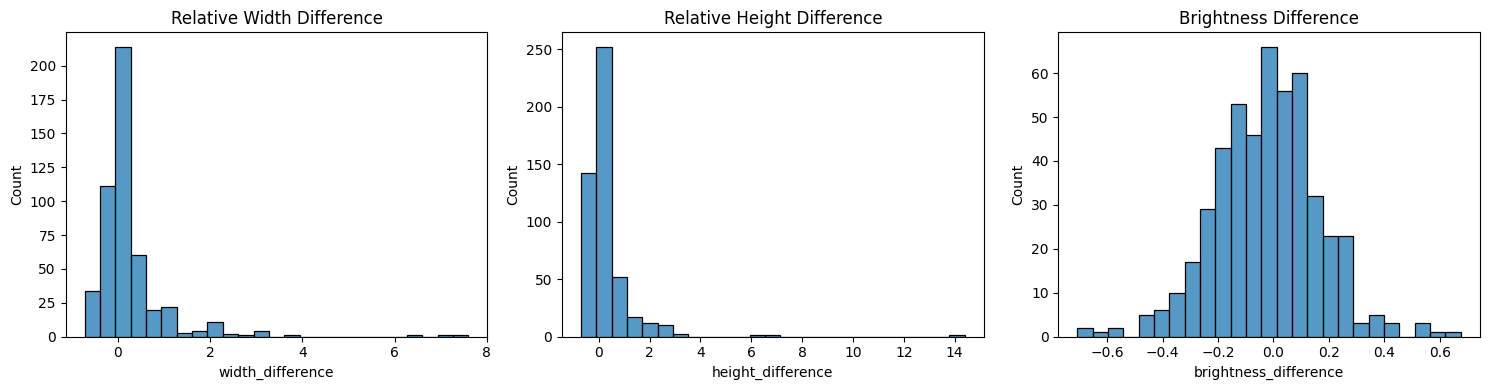

In [14]:
# 1. Collect unique image pairs from training and test

pair_data = pd.concat([
    train[["pair_id", "source_image", "target_image"]].drop_duplicates(),
    test[["pair_id", "source_image", "target_image"]].drop_duplicates()
], ignore_index=True).drop_duplicates(subset="pair_id")


# 2. Extract image characteristics

image_cache = {}

def get_image_stats(path):
    image = Image.open(DATA_DIR / path).convert("RGB")
    width, height = image.size

    image.thumbnail((256, 256))

    rgb = np.asarray(image).astype(float) / 255
    hsv = np.asarray(image.convert("HSV")).astype(float) / 255

    return {
        "width": width,
        "height": height,
        "aspect_ratio": width / height,
        "pixels": width * height,
        "mean_R": rgb[:, :, 0].mean(),
        "mean_G": rgb[:, :, 1].mean(),
        "mean_B": rgb[:, :, 2].mean(),
        "brightness": hsv[:, :, 2].mean(),
        "saturation": hsv[:, :, 1].mean()
    }


def cached_stats(path):
    if path not in image_cache:
        image_cache[path] = get_image_stats(path)
    return image_cache[path]


records = []

for _, row in pair_data.iterrows():
    source = cached_stats(row["source_image"])
    target = cached_stats(row["target_image"])

    record = {"pair_id": row["pair_id"]}

    for key, value in source.items():
        record[f"source_{key}"] = value

    for key, value in target.items():
        record[f"target_{key}"] = value

    records.append(record)

pair_stats = pd.DataFrame(records)

display(pair_stats.head())


# 3. Source-target dimension correlations

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.regplot(data=pair_stats, x="source_width", y="target_width",
            scatter_kws={"alpha": 0.5, "s": 20},
            line_kws={"linewidth": 1}, ax=axes[0])

sns.regplot(data=pair_stats, x="source_height", y="target_height",
            scatter_kws={"alpha": 0.5, "s": 20},
            line_kws={"linewidth": 1}, ax=axes[1])

sns.regplot(data=pair_stats, x="source_aspect_ratio", y="target_aspect_ratio",
            scatter_kws={"alpha": 0.5, "s": 20},
            line_kws={"linewidth": 1}, ax=axes[2])

axes[0].set_title("Source vs Target Width")
axes[1].set_title("Source vs Target Height")
axes[2].set_title("Source vs Target Aspect Ratio")

plt.tight_layout()
plt.show()


# 4. Dimension correlation matrix

dimension_corr = pair_stats[
    ["source_width", "target_width",
     "source_height", "target_height",
     "source_aspect_ratio", "target_aspect_ratio"]
].corr(method="spearman")

plt.figure(figsize=(9, 6))
sns.heatmap(dimension_corr, annot=True, cmap="coolwarm",
            vmin=-1, vmax=1, fmt=".2f")

plt.title("Source-Target Dimension Correlations")
plt.tight_layout()
plt.show()


# 5. Colour correlations

color_features = [
    "mean_R", "mean_G", "mean_B",
    "brightness", "saturation"
]

color_columns = (
    [f"source_{c}" for c in color_features] +
    [f"target_{c}" for c in color_features]
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    pair_stats[color_columns].corr(method="spearman"),
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Source-Target Colour Feature Correlations")
plt.tight_layout()
plt.show()


# 6. Source-target brightness and saturation comparisons

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.regplot(data=pair_stats, x="source_brightness",
            y="target_brightness",
            scatter_kws={"alpha": 0.5, "s": 20}, ax=axes[0])

sns.regplot(data=pair_stats, x="source_saturation",
            y="target_saturation",
            scatter_kws={"alpha": 0.5, "s": 20}, ax=axes[1])

axes[0].set_title("Source vs Target Brightness")
axes[1].set_title("Source vs Target Saturation")

plt.tight_layout()
plt.show()


# 7. Relative differences between source and target

pair_stats["width_difference"] = (
    pair_stats["target_width"] - pair_stats["source_width"]
) / pair_stats["source_width"]

pair_stats["height_difference"] = (
    pair_stats["target_height"] - pair_stats["source_height"]
) / pair_stats["source_height"]

pair_stats["aspect_ratio_difference"] = (
    pair_stats["target_aspect_ratio"] - pair_stats["source_aspect_ratio"]
)

pair_stats["brightness_difference"] = (
    pair_stats["target_brightness"] - pair_stats["source_brightness"]
)

pair_stats["saturation_difference"] = (
    pair_stats["target_saturation"] - pair_stats["source_saturation"]
)

display(pair_stats[
    ["width_difference", "height_difference",
     "aspect_ratio_difference", "brightness_difference",
     "saturation_difference"]
].describe().round(3))


# 8. Visualise relative differences

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(pair_stats["width_difference"], bins=25, ax=axes[0])
axes[0].set_title("Relative Width Difference")

sns.histplot(pair_stats["height_difference"], bins=25, ax=axes[1])
axes[1].set_title("Relative Height Difference")

sns.histplot(pair_stats["brightness_difference"], bins=25, ax=axes[2])
axes[2].set_title("Brightness Difference")

plt.tight_layout()
plt.show()